load the data

In [8]:
import pandas as pd

df = pd.read_csv(
    "../data/oncology_cohort_2026-11-18.csv.csv",
    parse_dates=["start_date", "primary_completion_date", "completion_date"]
)
print(df.shape)
df.head()

(10134, 13)


,nct_id,phase,overall_status,terminated_flag,start_date,primary_completion_date,completion_date,enrollment,enrollment_type,why_stopped,sponsor_class,india_flag,n_countries
0,NCT00329641,PHASE2,COMPLETED,0,2011-02-28,2012-11-30,2012-11-30,25.0,ACTUAL,NaN,NIH,0,1
1,NCT00448201,PHASE2,COMPLETED,0,2011-01-07,2011-01-11,2012-05-23,71.0,ACTUAL,NaN,OTHER,0,1
2,NCT00484341,PHASE2,COMPLETED,0,2010-10-31,2016-05-31,2016-05-31,69.0,ACTUAL,NaN,INDUSTRY,0,3
3,NCT00606723,PHASE3,COMPLETED,0,2010-04-30,2021-02-24,2021-02-24,154.0,ACTUAL,NaN,OTHER,0,3
4,NCT00615784,PHASE2,TERMINATED,1,2010-05-25,2013-10-01,2013-11-08,24.0,ACTUAL,Study terminated. Eisai's Targretin acquired b...,OTHER,0,1


basic counts and missing values

In [9]:
print(df["overall_status"].value_counts())
print(df.groupby("phase")["terminated_flag"].agg(["count", "mean"]))
print(df.isna().sum())

overall_status
COMPLETED     7513
TERMINATED    2621
Name: count, dtype: int64
               count      mean
phase                         
PHASE2          7663  0.273783
PHASE2/PHASE3    296  0.246622
PHASE3          2175  0.206897
nct_id                        0
phase                         0
overall_status                0
terminated_flag               0
start_date                    0
primary_completion_date       2
completion_date              48
enrollment                    5
enrollment_type               6
why_stopped                7681
sponsor_class                 0
india_flag                    0
n_countries                   0
dtype: int64


termination rate by start year (the late-year distortion check)

            count      mean
start_year                 
2010          924  0.230519
2011          991  0.225025
2012          871  0.227325
2013          844  0.215640
2014          809  0.233622
2015          859  0.236321
2016          775  0.225806
2017          852  0.245305
2018          761  0.275953
2019          629  0.295707
2020          575  0.318261
2021          558  0.353047
2022          356  0.367978
2023          216  0.393519
2024          114  0.324561


<Axes: title={'center': 'Termination rate by start year'}, xlabel='start_year'>

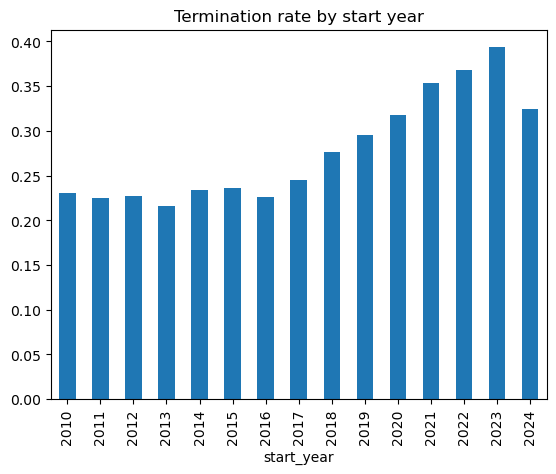

In [11]:
df["start_year"] = df["start_date"].dt.year
by_year = df.groupby("start_year")["terminated_flag"].agg(["count", "mean"])
print(by_year)
by_year["mean"].plot(kind="bar", title="Termination rate by start year")

enrollment and the “why stopped” coverage

In [12]:
print(df["enrollment"].describe())
print(df.groupby("overall_status")["enrollment"].median())

terminated = df[df["terminated_flag"] == 1]
print("Terminated:", len(terminated),
      "| with reason:", terminated["why_stopped"].notna().sum())

count    10129.000000
mean       142.881232
std        659.410611
min          1.000000
25%         20.000000
50%         48.000000
75%        127.000000
max      55999.000000
Name: enrollment, dtype: float64
overall_status
COMPLETED     62.0
TERMINATED    14.0
Name: enrollment, dtype: float64
Terminated: 2621 | with reason: 2453


sponsors and India

In [13]:
print(df.groupby("sponsor_class")["terminated_flag"].agg(["count", "mean"]))
print(df.groupby("india_flag")["terminated_flag"].agg(["count", "mean"]))

               count      mean
sponsor_class                 
FED                7  0.142857
INDIV              6  0.333333
INDUSTRY        3362  0.251338
NETWORK          238  0.193277
NIH              354  0.268362
OTHER           6071  0.266678
OTHER_GOV         93  0.139785
UNKNOWN            3  0.000000
            count      mean
india_flag                 
0            9995  0.259530
1             139  0.194245


In [14]:
core = df[df["start_year"].between(2010, 2017)]
print(core.shape, core["terminated_flag"].mean())
print(core.groupby("phase")["terminated_flag"].agg(["count", "mean"]))
print(core.groupby("india_flag")["terminated_flag"].agg(["count", "mean"]))
print(core.groupby("overall_status")["enrollment"].median())

(6925, 14) 0.2298916967509025
               count      mean
phase                         
PHASE2          5191  0.247351
PHASE2/PHASE3    197  0.203046
PHASE3          1537  0.174366
            count      mean
india_flag                 
0            6828  0.231107
1              97  0.144330
overall_status
COMPLETED     68.0
TERMINATED    15.0
Name: enrollment, dtype: float64
